# IBM Quantum | Vishnu Institute of Technology
## Qiskit Fall Fest 2026
### Challenge 4: Quantum Correlation Switch

---

### **Problem Statement**
In Challenge 3, how a quantum circuit can produce correlated outcomes was investigated.
Now, design a circuit that switches between correlated and opposite measurement outcomes.
Your goal is to create two different two-qubit behaviors using only a small number of quantum gates.

### **Your Task**
- **Part A – Correlated Outcomes:** Design a two-qubit circuit where measurement results are predominantly `00` and `11` (run 100 shots).
- **Part B – Opposite Outcomes:** Modify your circuit so that measurement results are predominantly `01` and `10` (run 100 shots).
- **Part C – Compare:** Compare the two circuits using histograms.

### **Design Constraints**
- Use exactly 2 qubits.
- Measure both qubits.
- Use no more than 4 quantum gates before measurement.
- Use only gates introduced during the workshop.
- Be created and executed using Qiskit.
- Use 100 shots for each experiment.

In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

simulator = AerSimulator()
shots = 100
print("Qiskit initialized successfully!")

Qiskit initialized successfully!


---
## 1. Think Before You Run (Predictions)

### **Questions & Answers:**
1. **Which outcomes should dominate in Part A?**
   - In Part A, we create the Bell state $|\Phi^+\rangle = \frac{|00\rangle + |11\rangle}{\sqrt{2}}$.
   - **`00` and `11` will dominate** (each ~50% probability).

2. **Which outcomes should dominate in Part B?**
   - In Part B, applying an $X$ gate flips qubit 1 to yield $|\Psi^+\rangle = \frac{|01\rangle + |10\rangle}{\sqrt{2}}$.
   - **`01` and `10` will dominate** (each ~50% probability).

3. **Will all four possible outcomes appear?**
   - **No.** Ideal quantum simulation yields strictly 2 outcomes for each circuit because the probability amplitudes for the other two states are exactly zero ($0\%$ probability).

4. **Why might some outcomes be much more frequent than others?**
   - Because the CNOT gate creates maximum quantum entanglement between the qubits. The probability amplitude is concentrated exclusively in two entangled states, leaving the remaining two states with zero probability.

In [2]:
# Part A: Correlated Outcomes (00 & 11)
qc_A = QuantumCircuit(2, 2, name="Part_A_Correlated")
qc_A.h(0)           # Hadamard gate (1 gate)
qc_A.cx(0, 1)       # CNOT gate (2 gates total <= 4)
qc_A.measure([0, 1], [0, 1])

print("--- Part A Circuit (Correlated Outcomes: 00, 11) ---")
print(qc_A.draw('text'))

counts_A = simulator.run(qc_A, shots=shots).result().get_counts()
print("Part A Results (100 shots):", counts_A)

--- Part A Circuit (Correlated Outcomes: 00, 11) ---
     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 
Part A Results (100 shots): {'00': 54, '11': 46}


In [3]:
# Part B: Opposite Outcomes (01 & 10) - Adding X gate switch
qc_B = QuantumCircuit(2, 2, name="Part_B_Opposite")
qc_B.h(0)
qc_B.cx(0, 1)
qc_B.x(1)           # Correlation switch: X gate (3 gates total <= 4)
qc_B.measure([0, 1], [0, 1])

print("--- Part B Circuit (Opposite Outcomes: 01, 10) ---")
print(qc_B.draw('text'))

counts_B = simulator.run(qc_B, shots=shots).result().get_counts()
print("Part B Results (100 shots):", counts_B)

--- Part B Circuit (Opposite Outcomes: 01, 10) ---
     ┌───┐          ┌─┐   
q_0: ┤ H ├──■───────┤M├───
     └───┘┌─┴─┐┌───┐└╥┘┌─┐
q_1: ─────┤ X ├┤ X ├─╫─┤M├
          └───┘└───┘ ║ └╥┘
c: 2/════════════════╩══╩═
                     0  1 
Part B Results (100 shots): {'10': 52, '01': 48}


---
## 2. Part C – Compare Using Histograms

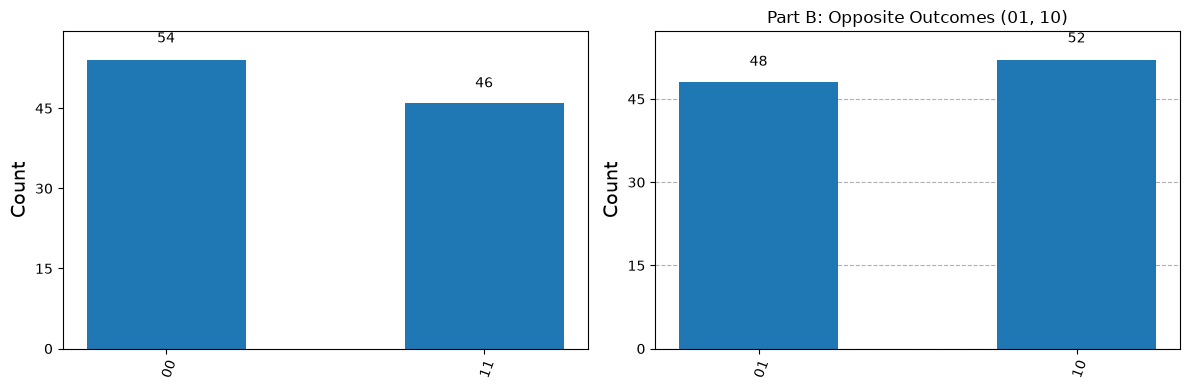

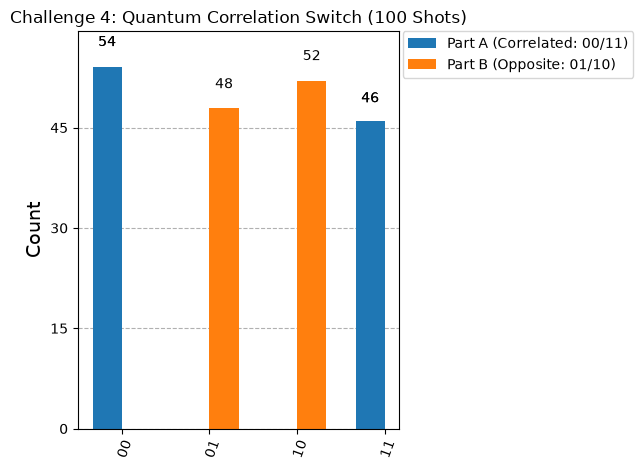

In [4]:
# Side-by-side Histograms
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_histogram(counts_A, ax=axes[0], title="Part A: Correlated (00, 11)")
plot_histogram(counts_B, ax=axes[1], title="Part B: Opposite (01, 10)")
plt.tight_layout()
plt.show()

# Combined Histogram
plot_histogram([counts_A, counts_B], 
               legend=["Part A (Correlated)", "Part B (Opposite)"], 
               title="Challenge 4: Comparison of Correlation Switch (100 Shots)")
plt.show()

---
## 3. Explanations (Required in Submission)

### **1. Which outcomes are dominant in Part A?**
- Outcomes **`00`** and **`11`** dominate Part A, each accounting for approximately 50% of the 100 measurement shots.

### **2. Which outcomes are dominant in Part B?**
- Outcomes **`01`** and **`10`** dominate Part B, each accounting for approximately 50% of the 100 measurement shots.

### **3. What changed between the two circuits?**
- A single **Pauli-$X$ (NOT) gate** was inserted on qubit 1 after creating the entangled pair.

### **4. Why did the measurement relationship change?**
- In Part A, the CNOT gate correlates the two qubits such that their values are always equal ($00$ and $11$).
- In Part B, the $X$ gate acts as a bit-flip on qubit 1. It transforms $|0\rangle \leftrightarrow |1\rangle$ on the second qubit without disrupting the underlying quantum superposition:
  $$|00\rangle \xrightarrow{X_1} |01\rangle$$
  $$|11\rangle \xrightarrow{X_1} |10\rangle$$
- Therefore, the measurement relationship flips from **directly correlated (same values)** to **anti-correlated (opposite values)**.

---
## 4. Comparison Summary Table

| Circuit | Quantum Gates | Resulting Bell State | Expected Outcomes | Actual Counts (100 Shots) | Nature of Correlation |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Part A** | $H(0), CX(0, 1)$ | $|\Phi^+\rangle = \frac{|00\rangle + |11\rangle}{\sqrt{2}}$ | ~50% `00`, ~50% `11` | {'00': 54, '11': 46} | **Directly Correlated** (Same) |
| **Part B** | $H(0), CX(0, 1), X(1)$ | $|\Psi^+\rangle = \frac{|01\rangle + |10\rangle}{\sqrt{2}}$ | ~50% `01`, ~50% `10` | {'10': 52, '01': 48} | **Anti-correlated** (Opposite) |